# Экзамен



In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from rink import plot_rink

pd.set_option('display.precision', 3)
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 20)
sns.set_theme(style='whitegrid')
%matplotlib inline

## 1. Чтение данных

В файле Excel первая колонка безымянная, это просто старый индекс строк (0, 1, 2, ...). Если её не убрать, получится 39 столбцов, а не 38, как в примере. Поэтому читаю с `index_col=0`, тогда эта колонка становится индексом и всё совпадает.

In [2]:
events = pd.read_excel('NHL-playoffs-2026.xlsx', index_col=0)
events.shape

(29710, 38)

In [3]:
events.iloc[:10, [2, 3, 4, 9, 12]]

,Date,Away Team,Home Team,Remaining Time,Play Type
0,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,period-start
1,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,faceoff
2,2026-04-19,Boston Bruins,Buffalo Sabres,19:47,hit
3,2026-04-19,Boston Bruins,Buffalo Sabres,19:46,hit
4,2026-04-19,Boston Bruins,Buffalo Sabres,19:41,hit
5,2026-04-19,Boston Bruins,Buffalo Sabres,19:27,hit
6,2026-04-19,Boston Bruins,Buffalo Sabres,19:03,hit
7,2026-04-19,Boston Bruins,Buffalo Sabres,18:53,missed-shot
8,2026-04-19,Boston Bruins,Buffalo Sabres,18:48,hit
9,2026-04-19,Boston Bruins,Buffalo Sabres,18:37,missed-shot


Размер `(29710, 38)`, первые строки точь-в-точь как в примере. Каждая строка это одно событие матча: вбрасывание, силовой приём, бросок и так далее. Посмотрим, каких событий сколько, это пригодится дальше:

In [4]:
events['Play Type'].value_counts()

Play Type
hit                5621
faceoff            4995
shot-on-goal       4137
stoppage           3958
blocked-shot       2798
missed-shot        2643
giveaway           2604
penalty             804
takeaway            779
goal                486
period-start        272
period-end          272
delayed-penalty     259
game-end             82
Name: count, dtype: int64

Больше всего силовых приёмов (hit) и вбрасываний, а голов всего 486 на весь плей-офф. `period-start`/`period-end` по 272, `game-end` 82, значит в данных 82 матча и 272 периода (то есть 272 - 3*82 = 26 овертаймов в сумме).

## 2. Сводная таблица по играм

Для каждой игры (`Game ID`) беру:
* дату и названия команд, они в пределах игры одинаковые, так что подходит `first`;
* счёт: поля `Cumulated Away Score` и `Cumulated Home Score` накопительные, поэтому итоговый счёт это их максимум по игре;
* число периодов: максимум `Period`. Если периодов 3, это `Final`, если 4, то `Final/OT`, если 5, то `Final/2OT` и так далее.

In [5]:
def outcome(periods):
    if periods <= 3:
        return 'Final'
    if periods == 4:
        return 'Final/OT'
    return f'Final/{periods - 3}OT'

games = events.groupby('Game ID').agg(**{
    'Date': ('Date', 'first'),
    'Away Team': ('Away Team', 'first'),
    'Home Team': ('Home Team', 'first'),
    'Away Score': ('Cumulated Away Score', 'max'),
    'Home Score': ('Cumulated Home Score', 'max'),
    'Periods': ('Period', 'max'),
})
games['Outcome'] = games['Periods'].map(outcome)
games = games.drop(columns='Periods')
games.columns

Index(['Date', 'Away Team', 'Home Team', 'Away Score', 'Home Score', 'Outcome'], dtype='str')

In [6]:
games.iloc[-5:, -4:]

,Home Team,Away Score,Home Score,Outcome
Game ID,,,,
2025030412,Carolina Hurricanes,3,4,Final/OT
2025030413,Vegas Golden Knights,4,5,Final/2OT
2025030414,Vegas Golden Knights,5,3,Final
2025030415,Carolina Hurricanes,2,4,Final
2025030416,Vegas Golden Knights,3,0,Final


Совпадает с примером. На всякий случай проверю, что счёт сходится с числом событий `goal` в каждой игре (если бы где-то была ошибка в накопительных полях, это бы вылезло):

In [7]:
goals_per_game = events[events['Play Type'] == 'goal'].groupby('Game ID').size()
print('Счёт совпадает с числом голов во всех играх:',
      (goals_per_game == games['Away Score'] + games['Home Score']).all())
games['Outcome'].value_counts()

Счёт совпадает с числом голов во всех играх: True


Outcome
Final        60
Final/OT     18
Final/2OT     4
Name: count, dtype: int64

Всё сходится. Из 82 матчей 60 закончились в основное время, 18 в первом овертайме и 4 во втором. Это 18 + 2*4 = 26 овертаймов, ровно столько, сколько и получилось по числу `period-start` в п. 1. В плей-офф овертаймы играются по 20 минут до первой заброшенной шайбы, без буллитов, поэтому бывают и двойные.

## 3. Функция `gameInfo`

Формат как в примере: сначала хозяева, потом гости, счёт в том же порядке, затем исход и дата.

In [8]:
def gameInfo(gameId):
    g = games.loc[gameId]
    return (f"{g['Home Team']} - {g['Away Team']} "
            f"({g['Home Score']} - {g['Away Score']}, {g['Outcome']}, {g['Date']})")

print(gameInfo(games.index.min()))
print(gameInfo(games.index.max()))

Buffalo Sabres - Boston Bruins (4 - 3, Final, 2026-04-19)
Vegas Golden Knights - Carolina Hurricanes (0 - 3, Final, 2026-06-14)


## 4. Сколько шайб забивают за матч

Просто складываю голы гостей и хозяев.

In [9]:
games['Total Score'] = games['Away Score'] + games['Home Score']
games['Total Score'].describe()

count    82.000
mean      5.927
std       2.260
min       1.000
25%       5.000
50%       6.000
75%       7.000
max      15.000
Name: Total Score, dtype: float64

В среднем почти 6 шайб за матч (5.93), медиана ровно 6, половина матчей укладывается в диапазон от 5 до 7 голов. Минимум 1 гол, максимум аж 15. Стандартное отклонение 2.26, то есть разброс вполне заметный.

## 5. Гистограмма числа голов

Величина дискретная, поэтому `countplot` подходит лучше, чем обычная гистограмма с бинами. Чтобы на оси были все значения от 1 до 15 (включая те, которых не было, например 12-14), задаю `order` явно.

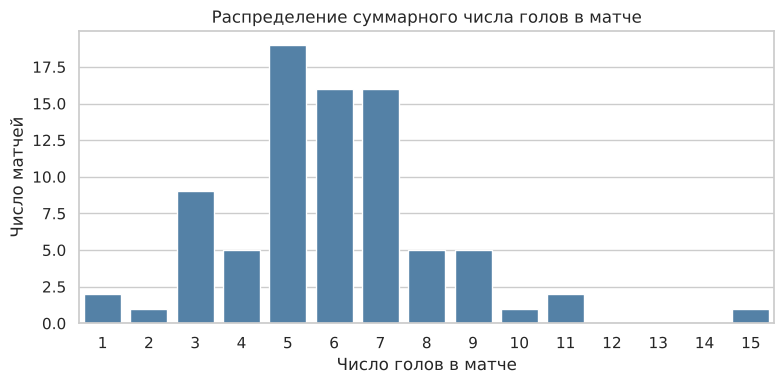

Total Score
1      2
2      1
3      9
4      5
5     19
6     16
7     16
8      5
9      5
10     1
11     2
15     1
Name: count, dtype: int64

In [10]:
plt.figure(figsize=(8, 4))
ax = sns.countplot(x=games['Total Score'], order=range(1, 16), color='steelblue')
ax.set_xlabel('Число голов в матче')
ax.set_ylabel('Число матчей')
ax.set_title('Распределение суммарного числа голов в матче')
plt.tight_layout()
plt.show()

games['Total Score'].value_counts().sort_index()

Что видно:
* Распределение одновершинное, основная масса матчей в диапазоне 3-7 голов, пик на 5 голах (19 матчей), чуть меньше на 6 и 7 (по 16).
* Есть заметный провал на 4 голах (5 матчей) рядом с всплеском на 3 (9 матчей). Скорее всего это просто случайность маленькой выборки, 82 матча это немного.
* Правый хвост длиннее левого: снизу всё ограничено единицей (0 голов в плей-офф вообще невозможно, ничьих нет, кто-то обязательно забьёт), а сверху бывают разгромы вроде 11 и 15 голов. Матч на 15 голов стоит особняком, следующий после него всего 11.
* Среднее (5.93) и медиана (6) почти совпадают, и в целом форма похожа на распределение Пуассона с параметром около 6. Для хоккея это довольно типично: голы это редкие и более-менее независимые события. У Пуассона дисперсия равна среднему, здесь дисперсия 2.26² ≈ 5.1, то есть даже чуть меньше среднего, разброс не больше «пуассоновского».
* Нечётные суммы (5, 7) встречаются часто, потому что многие матчи заканчиваются с разницей в одну шайбу.

## 6. Самые нерезультативные и самые результативные игры

Беру игры, где `Total Score` равен минимуму и максимуму соответственно (если таких несколько, выводятся все).

In [11]:
tmin, tmax = games['Total Score'].min(), games['Total Score'].max()
[gameInfo(i) for i in games.index[games['Total Score'] == tmin]]

['Montréal Canadiens - Tampa Bay Lightning (0 - 1, Final/OT, 2026-05-01)',
 'Philadelphia Flyers - Pittsburgh Penguins (1 - 0, Final/OT, 2026-04-29)']

In [12]:
[gameInfo(i) for i in games.index[games['Total Score'] == tmax]]

['Colorado Avalanche - Minnesota Wild (9 - 6, Final, 2026-05-03)']

Самые «сухие» игры это два матча 1:0, и оба закончились в овертайме, то есть 60 минут основного времени там вообще никто не забил. А самая результативная игра это Колорадо против Миннесоты, 9:6, 15 голов, причём без всяких овертаймов.

## 7. Сколько игроков участвовало в каждой игре

Беру все 14 колонок с игроками на льду (по 6 у каждой команды плюс отдельные колонки вратарей) и для каждой игры считаю число уникальных фамилий. Вратари и так попадают в колонки `Player on the Ice #1-6`, так что колонки `Goalie` ничего не добавят, но я их тоже включаю, как просит задание. Пропуски (`NaN`) не считаю.

Фамилии у разных людей в теории могли бы совпасть, но я проверил ниже: ни одно имя не встречается в двух разных командах, так что считать по полному имени безопасно.

In [13]:
onice_cols = [c for c in events.columns if 'Player on the Ice' in c or c.endswith('Goalie')]

player_count = events.groupby('Game ID')[onice_cols].apply(
    lambda d: pd.Series(d.values.ravel()).dropna().nunique())

players_tbl = pd.DataFrame({'Game Info': player_count.index.map(gameInfo),
                            'Player Count': player_count.values},
                           index=player_count.index)
players_tbl[players_tbl['Player Count'] == players_tbl['Player Count'].max()]

,Game Info,Player Count
Game ID,,
2025030216,"Montréal Canadiens - Buffalo Sabres (3 - 8, Fi...",40


In [14]:
player_count.value_counts().sort_index()

38    73
39     8
40     1
Name: count, dtype: int64

Почти во всех играх участвовало ровно 38 человек. Это логично: в заявку на матч в НХЛ входят 20 человек (18 полевых и 2 вратаря), но запасной вратарь обычно не выходит, так что от каждой команды на лёд выходят 19, а вместе 38. Значения 39 и 40 значат, что в игре меняли вратаря у одной или у обеих команд. Проверю это, посчитав, сколько разных вратарей было в каждой игре:

In [15]:
goalies_per_game = events.groupby('Game ID')[["Away Team's Goalie", "Home Team's Goalie"]].apply(
    lambda d: pd.Series(d.values.ravel()).dropna().nunique())
pd.crosstab(player_count.rename('Player Count'), goalies_per_game.rename('Goalies used'))

Goalies used,2,3,4
Player Count,,,
38,73,0,0
39,0,8,0
40,0,0,1


Так и есть: 39 игроков ровно там, где было 3 вратаря, а 40 там, где их было 4. Единственный матч с 40 участниками это разгром Монреаля Баффало 3:8 во втором раунде: в Монреале поменяли вратаря после пропущенных шайб, а в Баффало тоже была замена, так что на лёд вышли оба вратаря каждой команды.

In [16]:
names_teams = []
for side in ['Away', 'Home']:
    cols = [f"{side} Team's Player on the Ice #{i}" for i in range(1, 7)] + [f"{side} Team's Goalie"]
    for c in cols:
        names_teams.append(pd.DataFrame({'Game ID': events['Game ID'], 'Player': events[c],
                                         'Team': events[f'{side} Team']}))
appearances = pd.concat(names_teams).dropna().drop_duplicates()
print('Имён, которые встречаются больше чем в одной команде:',
      (appearances.groupby('Player')['Team'].nunique() > 1).sum())
print('Всего разных игроков в плей-офф:', appearances['Player'].nunique())

Имён, которые встречаются больше чем в одной команде: 0
Всего разных игроков в плей-офф: 372


## 8. Длина броска

Броски берём трёх типов: `shot-on-goal` и `goal` (в створ) и `missed-shot` (мимо). Тут нужно разобраться, в какие ворота бьёт команда:

* поле `Home Team's Defending Side` говорит, с какой стороны ворота хозяев **в этом периоде** (команды меняются сторонами каждый период, и это поле меняется вместе с ними);
* если хозяева защищают левые ворота (`left`), то хозяева атакуют правые, $X = 89$, а гости атакуют левые, $X = -89$; если `right`, то наоборот;
* кто бросает, понятно из сравнения `Team Making the Play` с `Home Team`.

Получается компактное правило: $X = 89$, если (бросают хозяева) == (хозяева защищают левые ворота), иначе $X = -89$.

Дальше считаем расстояние до ближайшей точки отрезка ворот (он идёт от $y=-3$ до $y=3$ при $x = X$). Если $y$ между -3 и 3, ближайшая точка прямо напротив и расстояние $|x - X|$. Иначе ближайшая точка это штанга, $y=\pm 3$. Обе ветки формулы можно записать одной: «обрезаем» $y$ до отрезка $[-3, 3]$ через `np.clip` и считаем обычное евклидово расстояние до этой точки. Это ровно та же кусочная формула из задания, просто короче.

Для удобства сразу заведу столбец `Shooter` (хозяева или гости), он ещё пригодится.

In [17]:
is_home = events['Team Making the Play'] == events['Home Team']
home_left = events["Home Team's Defending Side"] == 'left'
goal_X = np.where(is_home == home_left, 89, -89)

x = events['X Coordinate on the Ice Rink']
y = events['Y Coordinate on the Ice Rink']
dist = np.sqrt((x - goal_X) ** 2 + (y - np.clip(y, -3, 3)) ** 2)

shot_types = ['shot-on-goal', 'goal', 'missed-shot']
is_shot = events['Play Type'].isin(shot_types)
events['Shot Length'] = np.where(is_shot, dist, np.nan)
events['Shooter'] = np.where(is_home, 'home', 'away')

events[is_shot][['Game ID', 'Play Type', 'Shot Length']]

,Game ID,Play Type,Shot Length
7,2025030111,missed-shot,12.207
9,2025030111,missed-shot,12.000
12,2025030111,missed-shot,29.411
13,2025030111,shot-on-goal,62.169
19,2025030111,missed-shot,52.924
...,...,...,...
29695,2025030416,missed-shot,54.083
29696,2025030416,missed-shot,5.099
29704,2025030416,goal,46.239
29706,2025030416,missed-shot,60.926


Числа совпадают с примером. Проверю первый бросок руками: Баффало (хозяева) в 1-м периоде, хозяева защищают левые ворота, значит бьют в правые, $X=89$. Точка $(82, -13)$, $y<-3$, так что $d = \sqrt{(82-89)^2 + (-13+3)^2} = \sqrt{49+100} \approx 12.207$. Сходится.

Пропусков в длине броска нет, у всех бросков есть координаты:

In [18]:
print('Бросков без длины:', events.loc[is_shot, 'Shot Length'].isna().sum())
events.loc[is_shot].groupby('Play Type')['Shot Length'].describe()

Бросков без длины: 0


,count,mean,std,min,25%,50%,75%,max
Play Type,,,,,,,,
goal,486.0,26.006,28.090,1.0,9.000,19.013,31.941,187.216
missed-shot,2643.0,34.014,22.313,0.0,16.155,32.249,49.041,185.068
shot-on-goal,4137.0,37.405,29.990,0.0,16.643,33.377,48.508,188.215


## 9. Длина точных и неточных бросков

Точных бросков (в створ, включая голы) 4623, а неточных 2643, то есть выборки разного размера. Если рисовать обычные гистограммы с подсчётом штук, синяя будет просто выше, и сравнивать формы распределений будет неудобно. Поэтому рисую плотности: `stat='density'` и `common_norm=False`, тогда каждая гистограмма нормируется на свою подвыборку и площадь каждой равна 1.

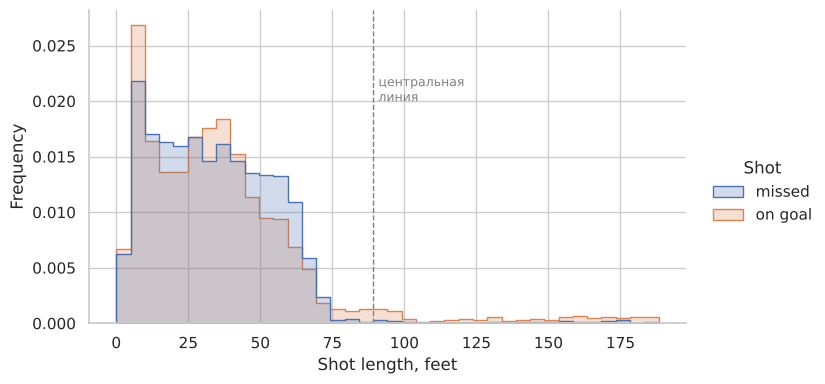

,count,mean,std,min,25%,50%,75%,max
Shot,,,,,,,,
missed,2643.0,34.014,22.313,0.0,16.155,32.249,49.041,185.068
on goal,4623.0,36.207,29.997,0.0,15.000,31.828,47.011,188.215


In [19]:
shots = events[is_shot].copy()
shots['Shot'] = np.where(shots['Play Type'] == 'missed-shot', 'missed', 'on goal')

g = sns.displot(data=shots, x='Shot Length', hue='Shot', hue_order=['missed', 'on goal'],
                stat='density', common_norm=False, binwidth=5, element='step',
                height=4, aspect=1.8)
g.set_axis_labels('Shot length, feet', 'Frequency')
plt.axvline(89, color='gray', ls='--', lw=1)
plt.text(91, 0.02, 'центральная\nлиния', color='gray', fontsize=9)
plt.show()

shots.groupby('Shot')['Shot Length'].describe()

Что видно из гистограммы:
* Основная масса бросков, и точных, и неточных, наносится с расстояния примерно до 60 футов, то есть из зоны атаки. Медианы почти одинаковые (около 32 футов).
* Самый высокий столбик у точных бросков на 5-10 футах: добивания, броски с пятачка, подставления. Совсем рядом с воротами попасть в створ проще. Хотя и неточных бросков вблизи много (их пик там же): шайба после подставления или с отскока легко уходит мимо.
* Дальше картина чередуется: на 10-25 футах относительно больше неточных (это часто броски с острого угла сбоку от ворот, где створ «узкий»), на 25-45 футах больше точных (броски из «домика» и кругов вбрасывания), а на 45-70 футах, то есть с синей линии, снова больше неточных. С дальней дистанции промахнуться легче, а кроме того, защитники с синей линии часто бросают не в створ, а «в сторону ворот» в расчёте на подставление.
* И самое интересное: у точных бросков длинный хвост на расстояниях больше 89 футов, то есть из-за центральной линии, со своей половины площадки. У неточных такого хвоста почти нет.

Почему так? Посмотрим на броски длиннее 89 футов (то есть из-за центральной линии) поподробнее. Тут есть тонкость: в строках с голом составы на льду записаны уже **после** гола (я на это наткнулся в пункте 21, там подробнее), поэтому вратаря, который был в воротах в момент броска, правильнее брать из предыдущего события той же игры.

In [20]:
prev = events.groupby('Game ID').shift(1)
events['Opp Goalie'] = np.where(is_home, events["Away Team's Goalie"], events["Home Team's Goalie"])
events['Opp Goalie Before'] = np.where(is_home, prev["Away Team's Goalie"], prev["Home Team's Goalie"])
# для всех событий, кроме гола, состав на момент события и есть правильный
events['Goalie In Net'] = np.where(events['Play Type'] == 'goal',
                                   events['Opp Goalie Before'], events['Opp Goalie'])

shots = events[is_shot].copy()
shots['Shot'] = np.where(shots['Play Type'] == 'missed-shot', 'missed', 'on goal')
shots['Long'] = shots['Shot Length'] > 89
shots['Empty Net'] = shots['Goalie In Net'].isna()

long_tbl = shots[shots['Long']].groupby('Play Type').agg(
    shots=('Shot Length', 'size'),
    empty_net=('Empty Net', 'sum'),
    median_period=('Period', 'median'),
)
long_tbl['share of all shots of this type'] = (
    long_tbl['shots'] / shots.groupby('Play Type').size())
long_tbl

,shots,empty_net,median_period,share of all shots of this type
Play Type,,,,
goal,19,16,3.0,0.039
missed-shot,30,23,3.0,0.011
shot-on-goal,202,0,2.0,0.049


In [21]:
shots[shots['Long']]['Play Zone'].value_counts()

Play Zone
Defensive    164
Neutral       87
Name: count, dtype: int64

Картина получается такая:

1. **Точные дальние броски с вратарём в воротах (`shot-on-goal`).** Их больше всего (202, это почти 5% всех бросков этого типа), и ни один из них не в пустые ворота (что логично: если шайбу «отбил вратарь», значит вратарь был). Это в основном не настоящие попытки забить, а выбросы шайбы из своей зоны (около 2/3 всех дальних бросков из зоны `Defensive`, остальные из средней зоны): защитник под давлением просто отправляет шайбу вдоль площадки, и она случайно летит в створ. Вратарь её спокойно ловит, а статистика всё равно засчитывает это как бросок в створ.
   При этом **неточный** выброс из своей зоны как бросок обычно вообще не фиксируется, это просто проброс (icing) или шайба, ушедшая за борт. Получается асимметрия в самой записи данных: дальний «бросок» попадает в статистику, в основном, когда летит в створ. Отсюда и длинный хвост у точных и почти нет хвоста у неточных.
2. **Броски в пустые ворота.** В конце третьего периода проигрывающая команда снимает вратаря ради шестого полевого. Тогда соперник бросает со своей половины уже всерьёз. Из 19 дальних голов 16 забиты в пустые ворота, и из 30 дальних промахов 23 тоже по пустым воротам (без вратаря такой промах засчитывается как бросок мимо). Медианный период у таких бросков третий, это тоже сходится.

То есть длинный хвост это не какое-то суперумение снайперов, а смесь «выбросов, которые случайно полетели в створ» и бросков по пустым воротам.

Ещё момент: у точных бросков есть небольшое количество значений около нуля и прямо у самой линии ворот, это добивания и подставления. А несколько бросков с расстоянием 0 это, скорее всего, неточность координат в данных (бросок записан прямо в точке ворот).

## 10. Доля точных бросков у каждой команды в каждой игре

Незаблокированные броски это `shot-on-goal`, `goal` и `missed-shot`. Точные среди них `shot-on-goal` и `goal`. Через `crosstab` считаю количества по типам для пары (игра, команда), и делю точные на сумму.

In [22]:
unblocked = events[is_shot]
numshots = pd.crosstab([unblocked['Game ID'], unblocked['Team Making the Play']],
                       unblocked['Play Type'])
numshots['Share of Shots on Goal'] = (numshots['shot-on-goal'] + numshots['goal']) / \
    numshots[shot_types].sum(axis=1)
numshots['Share of Shots on Goal']

Game ID     Team Making the Play
2025030111  Boston Bruins           0.625
            Buffalo Sabres          0.679
2025030112  Boston Bruins           0.614
            Buffalo Sabres          0.636
2025030113  Boston Bruins           0.694
                                    ...  
2025030414  Vegas Golden Knights    0.583
2025030415  Carolina Hurricanes     0.558
            Vegas Golden Knights    0.510
2025030416  Carolina Hurricanes     0.639
            Vegas Golden Knights    0.595
Name: Share of Shots on Goal, Length: 164, dtype: float64

In [23]:
numshots['Share of Shots on Goal'].describe()

count    164.000
mean       0.639
std        0.085
min        0.353
25%        0.583
50%        0.639
75%        0.689
max        0.860
Name: Share of Shots on Goal, dtype: float64

Совпадает с примером. В среднем у команды в матче точными оказываются около 64% незаблокированных бросков, то есть примерно 2 из 3. Разброс от матча к матчу заметный: стандартное отклонение 0.085, от 35% до 86%.

Интересно проверить, а помогает ли точность выигрывать. Сравню долю точных бросков у победителя и у проигравшего в каждой игре:

In [24]:
winner = pd.Series(np.where(games['Home Score'] > games['Away Score'],
                            games['Home Team'], games['Away Team']), index=games.index)
ns = numshots.reset_index()
ns['Won'] = ns['Team Making the Play'] == ns['Game ID'].map(winner)
print(ns.groupby('Won')['Share of Shots on Goal'].agg(['mean', 'median', 'count']))

w = ns[ns['Won']].set_index('Game ID')['Share of Shots on Goal']
l = ns[~ns['Won']].set_index('Game ID')['Share of Shots on Goal']
print('\nВ скольких играх победитель был точнее:', (w > l.loc[w.index]).mean().round(3))
print(stats.wilcoxon(w, l.loc[w.index]))

        mean  median  count
Won                        
False  0.646   0.644     82
True   0.632   0.639     82

В скольких играх победитель был точнее: 0.451
WilcoxonResult(statistic=np.float64(1488.0), pvalue=np.float64(0.3236444177919262))


Результат меня немного удивил: победители бросают **не точнее** проигравших, а даже чуть наоборот (63.2% против 64.6%), и победитель был точнее соперника только в 45% игр. Парный тест Уилкоксона (сравниваю победителя и проигравшего внутри одной игры) даёт p-value 0.32, то есть никакой значимой разницы нет.

Вывод: доля точных бросков сама по себе почти ничего не говорит о том, кто выиграет. Это можно объяснить так. Во-первых, гол это редкое событие (около 10% бросков в створ), и куда важнее, откуда бросают и как играет вратарь, чем просто попал ли бросок в створ. Во-вторых, есть эффект счёта: проигрывающая команда в концовке давит и бросает при любой возможности, в том числе из неудобных позиций, а ведущая играет осторожнее. Это может немного смещать доли.

Ещё оговорка: доля точных бросков по одной игре очень шумная, ведь у команды за матч около 40-50 незаблокированных бросков, и пара случайных промахов сдвигает долю на несколько процентов.

## 11. Самые точные и самые неточные команды

Усредняю долю точных бросков по всем играм каждой команды (среднее по матчам, а не общая доля по всем броскам, как в примере).

In [25]:
avgnumshots = numshots.groupby(level='Team Making the Play')['Share of Shots on Goal'].mean()
avgnumshots.nlargest(5)

Team Making the Play
Edmonton Oilers        0.706
Philadelphia Flyers    0.684
Dallas Stars           0.670
Minnesota Wild         0.656
Colorado Avalanche     0.653
Name: Share of Shots on Goal, dtype: float64

In [26]:
avgnumshots.nsmallest(5)

Team Making the Play
Pittsburgh Penguins    0.554
Utah Mammoth           0.599
Carolina Hurricanes    0.615
Tampa Bay Lightning    0.626
Buffalo Sabres         0.626
Name: Share of Shots on Goal, dtype: float64

In [27]:
games_played = pd.concat([games['Away Team'], games['Home Team']]).value_counts().rename('Games')
pd.concat([avgnumshots.rename('Share'), games_played], axis=1).sort_values('Share', ascending=False)

,Share,Games
Edmonton Oilers,0.706,6
Philadelphia Flyers,0.684,10
Dallas Stars,0.670,6
Minnesota Wild,0.656,11
Colorado Avalanche,0.653,13
Anaheim Ducks,0.649,12
Montréal Canadiens,0.644,19
Los Angeles Kings,0.642,4
Boston Bruins,0.638,6
Ottawa Senators,0.635,4


Самые точные: Эдмонтон (70.6%), Филадельфия, Даллас, Миннесота, Колорадо. Самые неточные: Питтсбург (55.4%), Юта, Каролина, Тампа и Баффало.

Что тут стоит заметить:
* Разница между лучшими и худшими приличная, около 15 процентных пунктов, но Эдмонтон, Питтсбург, Юта, Даллас сыграли всего по 6 матчей. На такой маленькой выборке среднее легко «уезжает», так что это скорее про конкретную серию, а не про стиль команды.
* Каролина в пятёрке самых неточных, но при этом выиграла Кубок Стэнли: в финале она обыграла Вегас 4-2 в серии (последний матч 3:0 в Вегасе). Это хорошо согласуется с выводом из прошлого пункта: точность сама по себе не главное. Каролина много бросает (в следующем пункте у неё одно из самых больших чисел бросков в створ), и даже при низкой доле точных бросков в створ у неё получается много.
* Вегас, второй финалист, тоже не в топе по точности.
* Низкая доля может значить и не «криво бросают», а стиль: команды, которые много бросают «на добивание», с острых углов или просто в сторону ворот, чтобы создать отскок, будут иметь больше промахов.

## 12. Среднее число бросков в створ и голов за игру

Бросок в створ по статистике НХЛ включает и голы (гол тоже бросок, который попал в створ), поэтому `Shot` это `shot-on-goal` + `goal`. Считаю по каждой паре (игра, команда), потом усредняю по играм команды.

Тут есть тонкость: если бы в какой-то игре команда не забила ни одного гола, то в `groupby` по событиям `goal` эта игра просто не появилась бы, и среднее посчиталось бы только по играм с голами (завышено). С `crosstab` по событиям `shot-on-goal` и `goal` это не проблема: бросков в створ у каждой команды в каждой игре много, так что строка есть всегда, а в колонке `goal` будет честный ноль.

In [28]:
sog = events[events['Play Type'].isin(['shot-on-goal', 'goal'])]
per_game = pd.crosstab([sog['Game ID'], sog['Team Making the Play']], sog['Play Type'])
per_game['Shot'] = per_game['shot-on-goal'] + per_game['goal']
per_game['Goal'] = per_game['goal']
print('Пар (игра, команда):', len(per_game), '(должно быть 82*2 = 164)')

avgshots = per_game.groupby(level='Team Making the Play')[['Shot', 'Goal']].mean()
avgshots.columns.name = None
avgshots

Пар (игра, команда): 164 (должно быть 82*2 = 164)


,Shot,Goal
Team Making the Play,,
Anaheim Ducks,31.667,3.250
Boston Bruins,25.167,2.000
Buffalo Sabres,30.462,3.308
Carolina Hurricanes,31.632,3.474
Colorado Avalanche,32.154,3.385
Dallas Stars,31.000,2.500
Edmonton Oilers,28.333,3.500
Los Angeles Kings,25.250,1.250
Minnesota Wild,28.727,3.727


Совпадает с примером. Больше всех в створ бросают Колорадо (32.2 за игру), Анахайм и Каролина. Меньше всех Монреаль (23.3), при этом Монреаль забивает 2.84 гола за игру, это очень эффективно. Самые «голодные» по голам Лос-Анджелес и Оттава, по 1.25 гола за игру, и обе вылетели в первом раунде за 4 матча.

## 13. Связаны ли броски и голы

Рисую `regplot` по 16 командам, подписываю все точки, чтобы было видно, кто где.

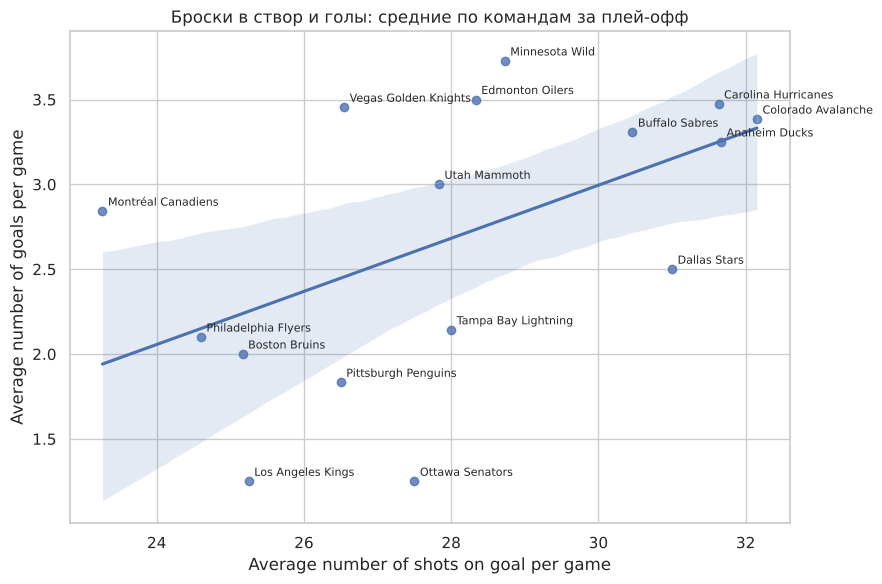

Корреляция r = 0.521, R^2 = 0.271, наклон = 0.156, p-value = 0.0386


In [29]:
plt.figure(figsize=(9, 6))
ax = sns.regplot(data=avgshots, x='Shot', y='Goal', ci=95)
for team, r in avgshots.iterrows():
    ax.annotate(team, (r['Shot'], r['Goal']), xytext=(4, 4), textcoords='offset points', fontsize=8)
ax.set_xlabel('Average number of shots on goal per game')
ax.set_ylabel('Average number of goals per game')
ax.set_title('Броски в створ и голы: средние по командам за плей-офф')
plt.tight_layout()
plt.show()

res = stats.linregress(avgshots['Shot'], avgshots['Goal'])
print(f'Корреляция r = {res.rvalue:.3f}, R^2 = {res.rvalue**2:.3f}, '
      f'наклон = {res.slope:.3f}, p-value = {res.pvalue:.4f}')

Связь видна, но умеренная. Линия регрессии идёт вверх: команды, которые больше бросают в створ, в среднем больше и забивают. Корреляция около 0.52, наклон около 0.16, то есть +1 бросок в створ за игру в среднем даёт +0.16 гола (что примерно соответствует средней реализации бросков ~10%). p-value около 0.04, формально значимо на 5%-ном уровне, но точек всего 16, и доверительный интервал (тень вокруг линии) очень широкий.

Отклонения от линии интересные:
* Монреаль сильно выше линии: бросает меньше всех, а забивает много. Видимо, броски у них качественные, или им попадались вратари послабее.
* Оттава и Лос-Анджелес сильно ниже: бросали по 25-27 раз, а забивали по 1.25. У них при этом всего по 4 игры, так что это может быть просто невезение или отличная игра вратаря соперника (Оттава играла против Каролины).
* Миннесота и Вегас выше линии, Даллас и Анахайм ниже.

Так что броски объясняют примерно четверть разброса в голах ($R^2 \approx 0.27$), а остальное это реализация моментов, качество бросков (с какой дистанции), игра вратарей и обычное везение на маленькой выборке. И важно не забывать, что у команд разное число игр (от 4 до 22), а все точки на графике весят одинаково.

## 14. Матч с наибольшим числом бросков

Тут считаю все попытки бросков: `shot-on-goal`, `goal`, `missed-shot` и `blocked-shot`.

In [30]:
all_shot_types = ['shot-on-goal', 'goal', 'missed-shot', 'blocked-shot']
all_shots = events[events['Play Type'].isin(all_shot_types)]
total_shots = all_shots.groupby('Game ID').size()
idxmax = total_shots.idxmax()
print(gameInfo(idxmax))
pd.DataFrame({'Game Info': total_shots.nlargest(5).index.map(gameInfo),
              'Shot attempts': total_shots.nlargest(5).values})

Carolina Hurricanes - Ottawa Senators (3 - 2, Final/2OT, 2026-04-20)


,Game Info,Shot attempts
0,"Carolina Hurricanes - Ottawa Senators (3 - 2, ...",208
1,"Minnesota Wild - Dallas Stars (3 - 2, Final/OT...",169
2,Vegas Golden Knights - Carolina Hurricanes (5 ...,163
3,Montréal Canadiens - Tampa Bay Lightning (0 - ...,156
4,"Vegas Golden Knights - Utah Mammoth (5 - 4, Fi...",154


Совпадает с примером: Каролина против Оттавы, 3:2 во втором овертайме, 208 попыток бросков. Тут всё понятно: матч шёл почти 5 периодов вместо трёх, вот и бросков больше. Второй и третий в списке тоже овертаймовые матчи, с большим отрывом от остальных.

Для честности можно пересчитать на 60 минут игры, тогда лидер может поменяться:

In [31]:
period_count = events.groupby('Game ID')['Period'].max()
# длина последнего периода берётся по максимальному Elapsed Time в нём
last_elapsed = events.groupby(['Game ID', 'Period'])['Elapsed Time'].max().groupby('Game ID').last()
last_min = last_elapsed.str.split(':').map(lambda t: int(t[0]) + int(t[1]) / 60)
minutes = 20 * (period_count - 1) + last_min
per60 = (total_shots / minutes * 60).rename('Shot attempts per 60 min')
pd.DataFrame({'Game Info': per60.nlargest(3).index.map(gameInfo), 'per 60': per60.nlargest(3).values})

,Game Info,per 60
0,"Buffalo Sabres - Boston Bruins (2 - 4, Final, ...",141.0
1,Montréal Canadiens - Carolina Hurricanes (0 - ...,140.0
2,"Colorado Avalanche - Los Angeles Kings (2 - 1,...",138.0


В расчёте на 60 минут в лидерах уже совсем другие матчи, все без овертаймов, около 140 попыток бросков за 60 минут. Так что рекорд Каролина - Оттава в основном из-за длины игры, а не из-за какого-то особенного темпа.

## 15. Карта бросков в этом матче

Нужно, чтобы гости всегда бросали в левые ворота, а хозяева в правые. В задании сказано отражать координаты в нечётных периодах, но это верно именно для этого матча (в нём хозяева защищают правые ворота в 1, 3 и 5 периодах). Я сделал универсальнее, через поле `Home Team's Defending Side`: если хозяева защищают правые ворота, то в этом периоде все броски нужно отразить, $(x, y) \to (-x, -y)$; если левые, то и так хозяева бьют вправо, а гости влево. Для этого матча это ровно то же самое, что отразить нечётные периоды, проверка ниже.

Для заблокированных бросков (`blocked-shot`) в поле `Team Making the Play` стоит команда, которая бросала (а не блокировала): это видно по координатам, они в зоне атаки бросающей команды. Так что их можно рисовать вместе с остальными. Координаты у них, правда, это место блока, а не место броска, но для картинки это неважно.

Хозяева показаны треугольником вправо (бьют в правые ворота), гости треугольником влево.

Period
1    right
2     left
3    right
4     left
5    right
Name: Home Team's Defending Side, dtype: str
Отражаем ровно нечётные периоды: True


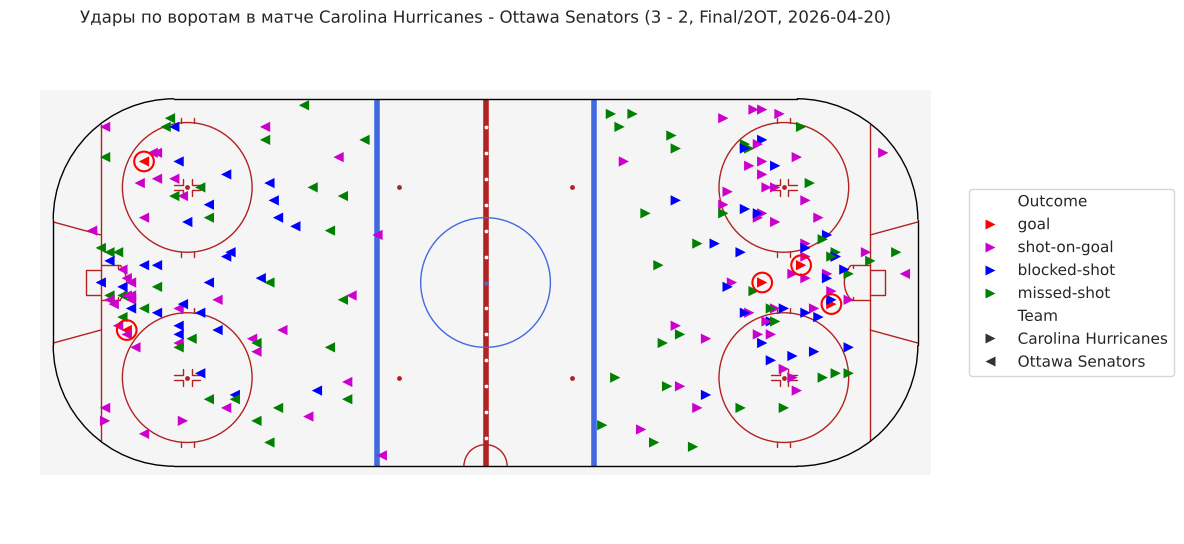

In [32]:
game = all_shots[all_shots['Game ID'] == idxmax].copy()
print(game.groupby('Period')["Home Team's Defending Side"].first())

flip = game["Home Team's Defending Side"] == 'right'
print('Отражаем ровно нечётные периоды:', (flip == (game['Period'] % 2 == 1)).all())

sign = np.where(flip, -1, 1)
game['x'] = game['X Coordinate on the Ice Rink'] * sign
game['y'] = game['Y Coordinate on the Ice Rink'] * sign
game = game.rename(columns={'Play Type': 'Outcome', 'Team Making the Play': 'Team'})

home, away = games.loc[idxmax, 'Home Team'], games.loc[idxmax, 'Away Team']
palette = {'goal': 'red', 'shot-on-goal': '#cc00cc', 'blocked-shot': 'blue', 'missed-shot': 'green'}

plt.figure(figsize=(12, 5.6))
plot_rink()
sns.scatterplot(data=game, x='x', y='y', hue='Outcome', hue_order=list(palette),
                palette=palette, style='Team', style_order=[home, away],
                markers={home: '>', away: '<'}, s=55, edgecolor='none')
# голы сделаю покрупнее, иначе они теряются
gg = game[game['Outcome'] == 'goal']
plt.scatter(gg['x'], gg['y'], s=200, facecolors='none', edgecolors='red', linewidths=1.5)
plt.axis('equal')
plt.axis('off')
plt.legend(loc='center left', bbox_to_anchor=(1.0, 0.5), frameon=True)
plt.title(f'Удары по воротам в матче {gameInfo(idxmax)}')
plt.tight_layout()
plt.show()

In [33]:
pd.crosstab(game['Team'], game['Outcome'], margins=True)

Outcome,blocked-shot,goal,missed-shot,shot-on-goal,All
Team,,,,,
Carolina Hurricanes,26,3,34,46,109
Ottawa Senators,28,2,32,37,99
All,54,5,66,83,208


По картинке:
* Броски обеих команд сгущаются в «домике» перед воротами (зона между кругами вбрасывания и до пятачка), это самая опасная зона. Много бросков и с синей линии, это броски защитников, и как раз среди них много заблокированных (синие треугольники ближе к синей линии): полевые игроки соперника успевают встать на пути шайбы.
* Голы (обведены кружком) забиты с близкого или среднего расстояния: три гола Каролины прямо от ворот, а у Оттавы один с пятачка и один из круга вбрасывания.
* Каролина (бросает вправо) нанесла чуть больше попыток бросков (109 против 99) и больше бросков в створ (49 против 39). Матч очень равный, что и подтверждает счёт 3:2 и два овертайма.
* Несколько точек есть и далеко от ворот, в средней зоне, это как раз те выбросы, про которые речь шла в п. 9.

## 16. Лучшие снайперы

Голы считаю по полю `Player in the Event #1` для событий `goal`. Группирую по паре (игрок, команда), чтобы в таблице сразу была видна команда (совпадений фамилий в разных командах нет, это проверено в п. 7). Если на 10-м месте несколько игроков с одинаковым числом, вывожу всех (`keep='all'`), иначе выбор между ними был бы произвольным.

In [34]:
G = events[events['Play Type'] == 'goal']
goals = G.groupby(['Player in the Event #1', 'Team Making the Play']).size()
goals.index.names = ['Player', 'Team']
goals = goals.rename('Goals')
goals.nlargest(10, keep='all').to_frame()

,,Goals
Player,Team,
Brett Howden,Vegas Golden Knights,14
Pavel Dorofeyev,Vegas Golden Knights,12
Logan Stankoven,Carolina Hurricanes,11
Mitch Marner,Vegas Golden Knights,10
Jordan Staal,Carolina Hurricanes,8
Nikolaj Ehlers,Carolina Hurricanes,8
Alex Newhook,Montréal Canadiens,7
Jackson Blake,Carolina Hurricanes,7
Mark Stone,Vegas Golden Knights,7


Лучший снайпер Бретт Хауден из Вегаса, 14 голов, на втором месте его одноклубник Павел Дорофеев (12), на третьем Логан Станковен из Каролины (11). В верхней части сплошь игроки двух финалистов, Вегаса и Каролины. Это естественно, потому что они сыграли больше всех матчей (22 и 19). С 7-го по 12-е место сразу шесть игроков по 7 голов, поэтому в списке больше 10 строк.

## 17. Лучшие ассистенты

Передачи это `Player in the Event #2` и `Player in the Event #3` у событий `goal` (первая и вторая голевые передачи). Склеиваю две колонки в одну, выкидываю пропуски (гол может быть вообще без передач или с одной) и считаю.

In [35]:
assists = pd.concat([
    G[['Player in the Event #2', 'Team Making the Play']].set_axis(['Player', 'Team'], axis=1),
    G[['Player in the Event #3', 'Team Making the Play']].set_axis(['Player', 'Team'], axis=1),
]).dropna(subset=['Player']).groupby(['Player', 'Team']).size().rename('Assists')
assists.nlargest(10, keep='all').to_frame()

,,Assists
Player,Team,
Jack Eichel,Vegas Golden Knights,20
Mitch Marner,Vegas Golden Knights,19
Jackson Blake,Carolina Hurricanes,13
Lane Hutson,Montréal Canadiens,13
Martin Necas,Colorado Avalanche,12
Nick Suzuki,Montréal Canadiens,12
Shea Theodore,Vegas Golden Knights,12
Taylor Hall,Carolina Hurricanes,12
Kirill Kaprizov,Minnesota Wild,11


Тут лидируют два вегасца: Джек Айкел (20 передач) и Митч Марнер (19). Дальше Джексон Блейк из Каролины и Лейн Хатсон из Монреаля по 13. Интересно, что Хатсон защитник, но для него это очень типично, он как раз силён в подключениях к атаке.

## 18. Гол + пас

Объединяю голы и передачи (игрок, у которого есть только голы или только передачи, получает 0 в другой колонке). Сортирую по очкам, при равенстве выше тот, у кого больше голов (так делает и сама НХЛ).

In [36]:
points = pd.concat([goals, assists], axis=1).fillna(0).astype(int)
points['Points'] = points['Goals'] + points['Assists']
points = points.sort_values(['Points', 'Goals'], ascending=False)
top_points = points[points['Points'] >= points['Points'].iloc[9]]
top_points

,,Goals,Assists,Points
Player,Team,,,
Mitch Marner,Vegas Golden Knights,10,19,29
Jack Eichel,Vegas Golden Knights,2,20,22
Jackson Blake,Carolina Hurricanes,7,13,20
Taylor Hall,Carolina Hurricanes,7,12,19
Brett Howden,Vegas Golden Knights,14,4,18
Nikolaj Ehlers,Carolina Hurricanes,8,10,18
Shea Theodore,Vegas Golden Knights,6,12,18
Pavel Dorofeyev,Vegas Golden Knights,12,4,16
Logan Stankoven,Carolina Hurricanes,11,5,16


Безоговорочный лидер плей-офф Митч Марнер: 29 очков (10+19), на 7 очков больше, чем у второго, Джека Айкела (2+20). Первые места снова у Вегаса и Каролины. Из других команд в десятку попали Ник Сузуки и Лейн Хатсон из Монреаля, который тоже прошёл далеко (до финала конференции, где проиграл Каролине, 19 матчей). На 8-11 местах четыре игрока по 16 очков, поэтому строк больше 10.

## 19. Больше всего бросков в створ за игру

Броски в створ это снова `shot-on-goal` + `goal` (бросающий в поле `Player in the Event #1`). А вот число сыгранных игр по событиям считать нельзя, иначе игрок, который сыграл матч, но ни разу не бросил, этот матч бы «потерял». Поэтому игры считаю по участию: в скольких матчах игрок хотя бы раз был на льду (таблица `appearances` из п. 7).

In [37]:
gp = appearances.groupby(['Player', 'Team'])['Game ID'].nunique().rename('GP')

sog_pl = sog.groupby(['Player in the Event #1', 'Team Making the Play']).size()
sog_pl.index.names = ['Player', 'Team']
sog_tbl = pd.concat([sog_pl.rename('Shots on goal'), gp], axis=1).fillna(0)
sog_tbl['Shots on goal'] = sog_tbl['Shots on goal'].astype(int)
sog_tbl['Per game'] = sog_tbl['Shots on goal'] / sog_tbl['GP']
sog_tbl.nlargest(10, 'Per game', keep='all')

,,Shots on goal,GP,Per game
Player,Team,,,
Jason Robertson,Dallas Stars,30,6,5.000
Dylan Guenther,Utah Mammoth,27,6,4.500
Nikita Kucherov,Tampa Bay Lightning,31,7,4.429
Matt Boldy,Minnesota Wild,48,11,4.364
Quinton Byfield,Los Angeles Kings,17,4,4.250
Darren Raddysh,Tampa Bay Lightning,28,7,4.000
Joel Eriksson Ek,Minnesota Wild,24,6,4.000
Alex Laferriere,Los Angeles Kings,15,4,3.750
David Pastrnak,Boston Bruins,22,6,3.667


Больше всех в среднем бросает Джейсон Робертсон из Далласа, 5 бросков в створ за игру. Дальше Дилан Гюнтер (Юта), Никита Кучеров (Тампа), Мэтт Болди (Миннесота). Тут много игроков из команд, которые рано вылетели (4-7 игр), в отличие от списков по голам и очкам, где важно было ещё и количество сыгранных матчей. Средние на малом числе игр, конечно, шумнее, но в этой десятке у всех минимум 4 игры (это минимальная длина серии), так что каких-то совсем случайных лидеров с одной игрой нет.

Из «долгоиграющих» выделяется Мэтт Болди: 48 бросков за 11 игр, 4.36 за игру, и он же в числе лучших снайперов.

## 20. Больше всего силовых приёмов за игру

Аналогично: `Player in the Event #1` у событий `hit`, делю на число сыгранных игр.

In [38]:
hits = events[events['Play Type'] == 'hit'].groupby(
    ['Player in the Event #1', 'Team Making the Play']).size()
hits.index.names = ['Player', 'Team']
hit_tbl = pd.concat([hits.rename('Hits'), gp], axis=1).fillna(0)
hit_tbl['Hits'] = hit_tbl['Hits'].astype(int)
hit_tbl['Per game'] = hit_tbl['Hits'] / hit_tbl['GP']
hit_tbl.nlargest(10, 'Per game', keep='all')

,,Hits,GP,Per game
Player,Team,,,
Lawson Crouse,Utah Mammoth,38,6,6.333
Alex Turcotte,Los Angeles Kings,6,1,6.000
Alexander Petrovic,Dallas Stars,6,1,6.000
Yakov Trenin,Minnesota Wild,51,9,5.667
Dylan Cozens,Ottawa Senators,22,4,5.500
Vasily Podkolzin,Edmonton Oilers,32,6,5.333
Carl Grundstrom,Philadelphia Flyers,15,3,5.000
Ivan Barbashev,Vegas Golden Knights,110,22,5.000
Marcus Foligno,Minnesota Wild,55,11,5.000


Тут уже видна проблема маленьких выборок: Александр Петрович (Даллас) и Алекс Туркотт (Лос-Анджелес) сыграли по одной игре и сделали в ней по 6 силовых, вот и 6.0 в среднем. Формально они в десятке, но это не очень показательно. Поэтому покажу ещё вариант, где учитываются только игроки, сыгравшие хотя бы 4 матча (это минимальная длина серии плей-офф, то есть игрок провёл хотя бы «одну серию»):

In [39]:
hit_tbl[hit_tbl['GP'] >= 4].nlargest(10, 'Per game', keep='all')

,,Hits,GP,Per game
Player,Team,,,
Lawson Crouse,Utah Mammoth,38,6,6.333
Yakov Trenin,Minnesota Wild,51,9,5.667
Dylan Cozens,Ottawa Senators,22,4,5.500
Vasily Podkolzin,Edmonton Oilers,32,6,5.333
Ivan Barbashev,Vegas Golden Knights,110,22,5.000
Marcus Foligno,Minnesota Wild,55,11,5.000
Owen Tippett,Philadelphia Flyers,29,6,4.833
William Carrier,Carolina Hurricanes,91,19,4.789
Colton Dach,Edmonton Oilers,23,5,4.600


Главный «силовик» плей-офф Лоусон Круз из Юты, больше 6 силовых за игру. Но если смотреть на тех, кто играл долго, впечатляют Иван Барбашев из Вегаса (110 силовых за 22 игры, ровно 5 за игру) и Уильям Карриер из Каролины (91 за 19, 4.8 за игру): держать такой темп весь плей-офф, до самого финала, очень тяжело. Ещё в списке Яков Тренин и Маркус Фолиньо из Миннесоты, это классические игроки «нижних» звеньев с силовой ролью.

## 21. Вратари, которые хотя бы в одном матче не пропустили ни одного гола

Идея: для каждой пары (игра, вратарь) посчитать, сколько голов забили, пока именно он стоял в воротах. Вратари, которые выходили на лёд в игре, но у которых 0 пропущенных, и есть ответ.

**Подвох, на который я наткнулся.** Самое очевидное решение: в строке с голом посмотреть, кто записан вратарём команды, которая пропустила. Но если присмотреться, состав на льду в строке гола записан уже **после** гола. Это хорошо видно на примерах:
* голы в овертайме: после гола матч закончился, и вратарь в этой строке уже `NaN`, как будто ворота были пустые;
* голы в пустые ворота в конце матча: вратарь в строке гола часто уже вернулся на лёд (к следующему вбрасыванию), хотя в предыдущих событиях его на льду не было;
* замена вратаря после пропущенной шайбы: в строке гола записан уже новый вратарь, и гол как будто пропустил он.

Вот несколько таких строк для наглядности:

In [40]:
G = events[events['Play Type'] == 'goal']
diff = G[G['Opp Goalie'].fillna('-') != G['Opp Goalie Before'].fillna('-')]
print('Голов, где вратарь в строке гола и в предыдущем событии различается:', len(diff), 'из', len(G))
diff[['Game ID', 'Period', 'Remaining Time', 'Team Making the Play',
      'Opp Goalie', 'Opp Goalie Before']].rename(
    columns={'Opp Goalie': 'Goalie in goal row', 'Opp Goalie Before': 'Goalie before goal'}).head(12)

Голов, где вратарь в строке гола и в предыдущем событии различается: 58 из 486


,Game ID,Period,Remaining Time,Team Making the Play,Goalie in goal row,Goalie before goal
364,2025030111,3,01:12,Buffalo Sabres,Jeremy Swayman,NaN
625,2025030112,3,19:44,Boston Bruins,Alex Lyon,Ukko-Pekka Luukkonen
1853,2025030115,4,10:46,Boston Bruins,NaN,Alex Lyon
2169,2025030116,3,03:20,Buffalo Sabres,Jeremy Swayman,NaN
2548,2025030121,4,18:38,Montréal Canadiens,NaN,Andrei Vasilevskiy
2977,2025030122,4,07:12,Tampa Bay Lightning,NaN,Jakub Dobes
3296,2025030123,4,17:51,Montréal Canadiens,NaN,Andrei Vasilevskiy
4351,2025030126,4,10:57,Tampa Bay Lightning,NaN,Jakub Dobes
5602,2025030132,5,06:07,Carolina Hurricanes,NaN,Linus Ullmark
6307,2025030134,3,02:22,Carolina Hurricanes,Linus Ullmark,NaN


Видно, например, что в овертаймах в строке гола вратаря нет, а в событии перед голом он был; и что в концовках матчей в строке гола вратарь «появляется», хотя до этого ворота были пустые. Поэтому правильнее брать вратаря из **предыдущего события той же игры**: это последнее зафиксированное состояние перед голом. Я это уже сделал в п. 9 (колонка `Opp Goalie Before`).

Голы в пустые ворота (вратаря перед голом нет) никому из вратарей не засчитываются, так и в официальной статистике НХЛ.

Список вратарей, выходивших в игре, беру из колонок `Away Team's Goalie` и `Home Team's Goalie` по всем событиям.

In [41]:
gl = pd.concat([
    pd.DataFrame({'Game ID': events['Game ID'], 'Goalie': events[f"{s} Team's Goalie"],
                  'Team': events[f'{s} Team']}) for s in ['Away', 'Home']
]).dropna().drop_duplicates()

ga = G.groupby(['Game ID', 'Opp Goalie Before']).size().rename('Goals Against')
ga.index.names = ['Game ID', 'Goalie']
gl = gl.merge(ga.reset_index(), on=['Game ID', 'Goalie'], how='left').fillna({'Goals Against': 0})

clean = gl[gl['Goals Against'] == 0].copy()
clean['Game Info'] = clean['Game ID'].map(gameInfo)
clean = clean.sort_values(['Goalie', 'Game ID']).set_index(['Goalie', 'Game ID'])
clean[['Team', 'Game Info']]

Team                                          Game Info
Goalie               Game ID                                                                           
Alex Lyon            2025030112       Buffalo Sabres  Buffalo Sabres - Boston Bruins (2 - 4, Final, ...
Andrei Vasilevskiy   2025030126  Tampa Bay Lightning  Montréal Canadiens - Tampa Bay Lightning (0 - ...
Brandon Bussi        2025030416  Carolina Hurricanes  Vegas Golden Knights - Carolina Hurricanes (0 ...
Dan Vladar           2025030142  Philadelphia Flyers  Pittsburgh Penguins - Philadelphia Flyers (0 -...
                     2025030146  Philadelphia Flyers  Philadelphia Flyers - Pittsburgh Penguins (1 -...
Frederik Andersen    2025030131  Carolina Hurricanes  Carolina Hurricanes - Ottawa Senators (2 - 0, ...
                     2025030221  Carolina Hurricanes  Carolina Hurricanes - Philadelphia Flyers (3 -...
                     2025030314  Carolina Hurricanes  Montréal Canadiens - Carolina Hurricanes (0 - ...
Joonas Korpisalo     2025030114        Boston Bruins  Boston Bruins - Buffalo Sabres (1 - 6, Final, ...
Scott Wedgewood      2025030235   Colorado Avalanche  Colorado Avalanche - Minnesota Wild (4 - 3, Fi...
Ukko-Pekka Luukkonen 2025030216       Buffalo Sabres  Montréal Canadiens - Buffalo Sabres (3 - 8, Fi...

In [42]:
clean.groupby(level='Goalie').size().sort_values(ascending=False).rename('Games with 0 GA')

Goalie
Frederik Andersen       3
Dan Vladar              2
Andrei Vasilevskiy      1
Alex Lyon               1
Brandon Bussi           1
Joonas Korpisalo        1
Scott Wedgewood         1
Ukko-Pekka Luukkonen    1
Name: Games with 0 GA, dtype: int64

**Ответ:** вратари, которые хотя бы в одном матче не пропустили ни одного гола:

In [43]:
sorted(clean.index.get_level_values('Goalie').unique())

['Alex Lyon',
 'Andrei Vasilevskiy',
 'Brandon Bussi',
 'Dan Vladar',
 'Frederik Andersen',
 'Joonas Korpisalo',
 'Scott Wedgewood',
 'Ukko-Pekka Luukkonen']

Тут есть два вида «сухих» матчей:
* **Полноценные шатауты**, когда вратарь отстоял весь матч, а его команда победила с нулём у соперника (например, Фредерик Андерсен трижды, Дэн Владар дважды, Андрей Василевский в победе 1:0 в овертайме, Брэндон Басси в финальном матче 3:0).
* **Неполные матчи**, о которых говорится в задании: вратарь вышел на замену и ничего не пропустил, хотя его команда могла и проиграть. Я проверил каждый такой случай по событиям:
  * Укко-Пекка Луукконен (Баффало) в матче в Монреале (8:3 в пользу Баффало): Алекс Лайон пропустил 3 шайбы и был заменён в середине первого периода, Луукконен доиграл матч, и после его выхода Монреаль больше не забил ни разу (все остальные голы в матче забивал Баффало).
  * Алекс Лайон (Баффало) в матче с Бостоном (2:4): Луукконен пропустил 4 шайбы, Лайон вышел в начале третьего периода и ничего не пропустил.
  * Йоонас Корписало (Бостон) в матче с Баффало (1:6): заменил Джереми Свеймана после шестой шайбы в третьем периоде.
  * Скотт Уэджвуд (Колорадо) в матче с Миннесотой: Маккензи Блэквуд пропустил 3 гола в первом периоде, Уэджвуд вышел со второго периода, не пропустил ничего, и Колорадо отыгрался и победил 4:3 в овертайме.

Для сравнения, если бы я брал вратаря прямо из строки гола, список получился бы неправильный:

In [44]:
ga_naive = G.groupby(['Game ID', 'Opp Goalie']).size().rename('GA naive')
ga_naive.index.names = ['Game ID', 'Goalie']
cmp = gl.merge(ga_naive.reset_index(), on=['Game ID', 'Goalie'], how='left').fillna({'GA naive': 0})
wrong = cmp[(cmp['Goals Against'] == 0) != (cmp['GA naive'] == 0)].copy()
wrong['Game Info'] = wrong['Game ID'].map(gameInfo)
wrong

,Game ID,Goalie,Team,Goals Against,GA naive,Game Info
22,2025030146,Arturs Silovs,Pittsburgh Penguins,1.0,0.0,Philadelphia Flyers - Pittsburgh Penguins (1 -...
52,2025030216,Ukko-Pekka Luukkonen,Buffalo Sabres,0.0,1.0,"Montréal Canadiens - Buffalo Sabres (3 - 8, Fi..."
82,2025030413,Brandon Bussi,Carolina Hurricanes,1.0,0.0,Vegas Golden Knights - Carolina Hurricanes (5 ...
88,2025030112,Alex Lyon,Buffalo Sabres,0.0,1.0,"Buffalo Sabres - Boston Bruins (2 - 4, Final, ..."
99,2025030126,Jakub Dobes,Montréal Canadiens,1.0,0.0,Montréal Canadiens - Tampa Bay Lightning (0 - ...


Наивный способ, например, «дарит» сухой матч вратарям, которые проиграли в овертайме (ведь овертаймный гол записан с `NaN` в воротах), и, наоборот, отнимает его у вратарей, которые вышли на замену (им приписывается гол, после которого их и выпустили). Так что учёт порядка событий тут реально важен.

## 22. Свой вопрос: насколько важно забить первым и есть ли преимущество своей площадки?

В хоккее есть расхожее мнение, что первый гол очень важен, а в плей-офф особенно: команды играют плотно, и отыгрываться тяжело. Ещё говорят, что дома играть легче (своя публика, последняя смена за хозяевами). Проверю на данных:
1. Как часто побеждает команда, забившая первой?
2. Как часто побеждает команда, которая ведёт после 1-го и после 2-го периода, и как это зависит от размера преимущества?
3. Есть ли преимущество своей площадки?

In [45]:
games['Winner'] = winner
first_goal = G.sort_values(['Game ID', 'Play ID']).groupby('Game ID')['Team Making the Play'].first()
fg_win = first_goal == games['Winner']
print(f'Команда, забившая первой, выиграла {fg_win.sum()} из {len(fg_win)} матчей ({fg_win.mean():.1%})')
print(f'Биномиальный тест против 50%: p-value = {stats.binomtest(fg_win.sum(), len(fg_win)).pvalue:.4f}')

home_win = games['Home Score'] > games['Away Score']
print(f'\nХозяева выиграли {home_win.sum()} из {len(home_win)} матчей ({home_win.mean():.1%})')
print(f'Биномиальный тест против 50%: p-value = {stats.binomtest(home_win.sum(), len(home_win)).pvalue:.4f}')

Команда, забившая первой, выиграла 56 из 82 матчей (68.3%)
Биномиальный тест против 50%: p-value = 0.0012

Хозяева выиграли 39 из 82 матчей (47.6%)
Биномиальный тест против 50%: p-value = 0.7407


Теперь счёт после каждого периода. Беру последнее событие периода (это `period-end`) и разницу накопленного счёта «хозяева минус гости».

In [46]:
period_end = events[events['Play Type'] == 'period-end'].set_index(['Game ID', 'Period'])
lead = (period_end['Cumulated Home Score'] - period_end['Cumulated Away Score']).unstack()

rows = []
for p in [1, 2]:
    d = lead[p]
    leader_won = np.sign(d) == np.where(home_win, 1, -1)
    rows.append({'After period': p,
                 'Tied games': (d == 0).sum(),
                 'Games with a leader': (d != 0).sum(),
                 'Leader won': leader_won[d != 0].sum(),
                 'Leader win %': leader_won[d != 0].mean()})
pd.DataFrame(rows).set_index('After period')

,Tied games,Games with a leader,Leader won,Leader win %
After period,,,,
1,27,55,39,0.709
2,25,57,46,0.807


In [47]:
d2 = lead[2]
tab = pd.DataFrame({'Lead after 2nd': d2.abs().clip(upper=3), 'Leader won':
                    (np.sign(d2) == np.where(home_win, 1, -1))})
tab = tab[tab['Lead after 2nd'] > 0]
by_lead = tab.groupby('Lead after 2nd')['Leader won'].agg(['mean', 'count'])
by_lead.index = by_lead.index.map({1: '1 гол', 2: '2 гола', 3: '3+ гола'})
by_lead

,mean,count
Lead after 2nd,,
1 гол,0.690,29
2 гола,0.875,16
3+ гола,1.000,12


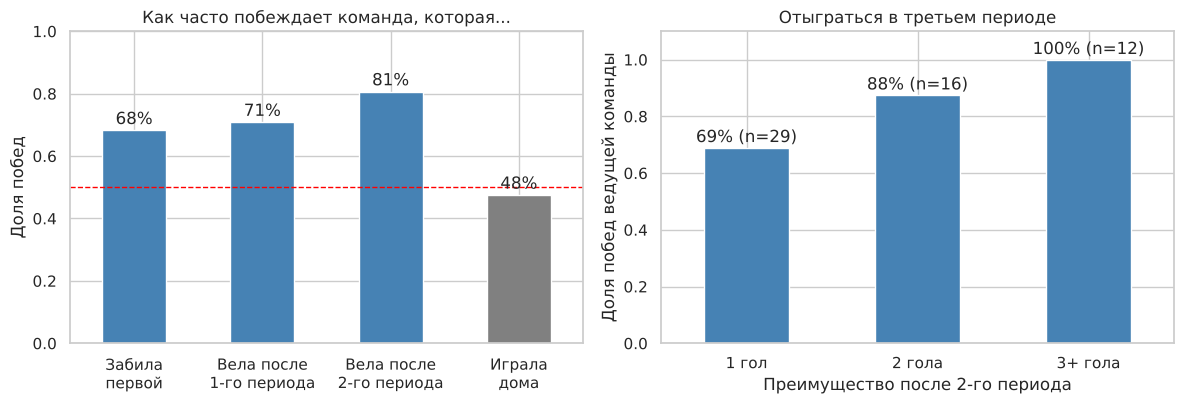

In [48]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

summary = pd.Series({
    'Забила\nпервой': fg_win.mean(),
    'Вела после\n1-го периода': rows[0]['Leader win %'],
    'Вела после\n2-го периода': rows[1]['Leader win %'],
    'Играла\nдома': home_win.mean(),
})
ax = summary.plot.bar(ax=axes[0], color=['steelblue'] * 3 + ['gray'], rot=0)
ax.axhline(0.5, color='red', ls='--', lw=1)
ax.set_ylim(0, 1)
ax.set_ylabel('Доля побед')
ax.set_title('Как часто побеждает команда, которая...')
for i, v in enumerate(summary):
    ax.text(i, v + 0.02, f'{v:.0%}', ha='center')

ax = by_lead['mean'].plot.bar(ax=axes[1], color='steelblue', rot=0)
ax.set_ylim(0, 1.1)
ax.set_xlabel('Преимущество после 2-го периода')
ax.set_ylabel('Доля побед ведущей команды')
ax.set_title('Отыграться в третьем периоде')
for i, (v, n) in enumerate(zip(by_lead['mean'], by_lead['count'])):
    ax.text(i, v + 0.02, f'{v:.0%} (n={n})', ha='center')
plt.tight_layout()
plt.show()

И последнее: а когда команды вообще отыгрывались? Посмотрю на матчи, которые выиграла команда, проигрывавшая после двух периодов:

In [49]:
comeback = (np.sign(d2) == np.where(home_win, -1, 1)) & (d2 != 0)
pd.DataFrame({'Game Info': games.index[comeback].map(gameInfo),
              'Score after 2 (home-away)': [f"{period_end.loc[(i, 2), 'Cumulated Home Score']}-"
                                             f"{period_end.loc[(i, 2), 'Cumulated Away Score']}"
                                             for i in games.index[comeback]]},
             index=games.index[comeback])

,Game Info,Score after 2 (home-away)
Game ID,,
2025030111,"Buffalo Sabres - Boston Bruins (4 - 3, Final, ...",0-1
2025030122,Tampa Bay Lightning - Montréal Canadiens (3 - ...,1-2
2025030124,Montréal Canadiens - Tampa Bay Lightning (2 - ...,2-1
2025030163,"Minnesota Wild - Dallas Stars (3 - 4, Final/2O...",3-2
2025030164,"Minnesota Wild - Dallas Stars (3 - 2, Final/OT...",1-2
2025030171,"Vegas Golden Knights - Utah Mammoth (4 - 2, Fi...",1-2
2025030181,"Edmonton Oilers - Anaheim Ducks (4 - 3, Final,...",2-3
2025030222,Carolina Hurricanes - Philadelphia Flyers (3 -...,1-2
2025030235,"Colorado Avalanche - Minnesota Wild (4 - 3, Fi...",1-3


**Выводы по моему вопросу:**

1. **Первый гол действительно важен.** Команда, открывшая счёт, выиграла примерно 68% матчей (56 из 82). Если бы первый гол ничего не значил, было бы около 50%; биномиальный тест даёт маленькое p-value, так что это не случайность. Хотя «стопроцентной» гарантией первый гол не является: почти треть матчей выигрывает команда, пропустившая первой.
2. **Чем позже, тем важнее преимущество.** После первого периода ведущая команда выигрывает чаще, после второго ещё чаще. А если после двух периодов ведёшь в две шайбы и больше, то шансы соперника отыграться совсем небольшие (см. правый график). Камбэков после двух периодов было всего 11 (таблица выше), из них 9 при отставании в одну шайбу и только 2 при отставании в две: Колорадо отыгрался с 1:3 против Миннесоты (тот самый матч с заменой вратаря из п. 21) и Каролина с 0:2 против Вегаса в финале. При отставании в три шайбы и больше не отыгрался никто (12 из 12).
3. **Преимущества своей площадки в этом плей-офф не было.** Хозяева выиграли даже меньше половины матчей (39 из 82, около 48%), и тест показывает, что это не отличается от 50% (p-value 0.74). Казалось бы, серии специально устроены так, что команда, лучше выступившая в регулярке, получает больше домашних игр, но на практике в этом сезоне это ничего не давало.

Оговорка: 82 матча это немного, и матчи внутри одной серии не независимы (одни и те же команды играют друг с другом до 7 раз), так что p-value здесь стоит воспринимать как ориентир, а не как строгий результат. Да и связь «первый гол → победа» не обязательно причинная: часто первой забивает просто более сильная команда, которая выиграла бы и так.